# NYU Depth v2: Depth Anything 3 vs Marigold V2 vs ZoeDepth vs DPT vs MiDaS (Kaggle)

**Kaggle setup:** *Add Input* → an NYU Depth v2 dataset · *Settings* → **Accelerator: GPU (T4 or P100)** and **Internet: On**. Run all cells top to bottom.

| # | Model | Variant | Output | Runs |
|---|---|---|---|---|
| 1 | **Depth Anything 3** (main) | `DA3MONO-LARGE` | relative depth | in the notebook |
| 2 | **Marigold V2** (main) | `Log-stage2` (official repo) | affine-invariant log depth | official script, launched from Section 5 |
| 3 | ZoeDepth | ZoeD-N | metric depth | in the notebook |
| 4 | DPT | DPT-Large | relative inverse depth | in the notebook |
| 5 | MiDaS | v2.1 | relative inverse depth | in the notebook |

**Marigold V2 is the risky step on a free GPU.** Its model card quotes about 17 GB of GPU memory at 1024² (a free Kaggle GPU has 16 GB), it downloads a large base model (Qwen-Image-Edit-2509, quantised to 4-bit), and its setup script uses conda. NYU images are only 480×640, so memory may be lower, but I could not verify that. **The notebook is built so a failure in Marigold V2 does not stop the rest:** it prints the reason, and you still get the other four models. Each model is also loaded inside `try/except`, so one broken install (e.g. DA3's `xformers`) skips that model instead of crashing the run.

All models are scored with a per-image affine alignment in their own output space. ZoeDepth-N was fine-tuned on NYU (in-domain); the others are zero-shot.

## 1. Setup

In [1]:
!pip -q install "transformers>=4.45" timm datasets accelerate scipy pandas matplotlib opencv-python-headless h5py huggingface_hub xformers depth-anything-3

ERROR: Ignored the following versions that require a different python version: 0.1.0 Requires-Python >=3.9,<=3.13; 0.1.1 Requires-Python >=3.9,<=3.13
ERROR: Could not find a version that satisfies the requirement depth-anything-3 (from versions: none)
ERROR: No matching distribution found for depth-anything-3


In [2]:
import os, time, warnings
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")

# Optional: silences the "unauthenticated requests" warning and speeds up downloads
# os.environ["HF_TOKEN"] = "hf_..."

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_IMAGES = 100          # 654 = full official NYU test set
os.makedirs("results", exist_ok=True)
print("device:", DEVICE, "| torch", torch.__version__)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "| %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 2**30))
import shutil
for p in ["/kaggle/working", "/tmp"]:
    if os.path.isdir(p): print(p, "free disk: %.1f GB" % (shutil.disk_usage(p).free / 2**30))

device: cuda | torch 2.11.0+cu130
GPU: Tesla T4 | 14.6 GB
/kaggle/working free disk: 19.5 GB
/tmp free disk: 966.9 GB


## 2. Metrics and alignment

In [3]:
import numpy as np

MIN_D, MAX_D = 1e-3, 10.0   # NYU range (m); use 80 for KITTI

def valid_mask(gt):
    return (gt > MIN_D) & (gt < MAX_D) & np.isfinite(gt)

def align_disparity_lsq(pred_disp, gt_depth, mask):
    """MiDaS protocol: per-image least-squares scale+shift in disparity space -> depth."""
    g = 1.0 / gt_depth[mask]; p = pred_disp[mask]
    A = np.stack([p, np.ones_like(p)], 1)
    (s, t), *_ = np.linalg.lstsq(A, g, rcond=None)
    disp = np.clip(s * pred_disp + t, 1.0 / MAX_D, 1.0 / MIN_D)
    return 1.0 / disp

def align_median(pred_depth, gt_depth, mask):
    s = np.median(gt_depth[mask]) / max(np.median(pred_depth[mask]), 1e-6)
    return np.clip(pred_depth * s, MIN_D, MAX_D)

def depth_metrics(pred, gt, mask):
    p, g = np.clip(pred[mask], MIN_D, None), gt[mask]
    thr = np.maximum(p / g, g / p)
    diff = p - g
    dlog = np.log(p) - np.log(g)
    return dict(
        AbsRel=float(np.mean(np.abs(diff) / g)),
        SqRel=float(np.mean(diff ** 2 / g)),
        RMSE=float(np.sqrt(np.mean(diff ** 2))),
        RMSElog=float(np.sqrt(np.mean(dlog ** 2))),
        log10=float(np.mean(np.abs(np.log10(p) - np.log10(g)))),
        SILog=float(100 * np.sqrt(max(np.mean(dlog ** 2) - np.mean(dlog) ** 2, 0))),
        d1=float(np.mean(thr < 1.25)),
        d2=float(np.mean(thr < 1.25 ** 2)),
        d3=float(np.mean(thr < 1.25 ** 3)))

def _lsq(p, y):
    A = np.stack([p, np.ones_like(p)], 1)
    (s, t), *_ = np.linalg.lstsq(A, y, rcond=None)
    return s, t

def align_affine_depth(pred, gt, mask):
    """Affine-invariant DEPTH output (e.g. Depth Anything 3 mono): fit s*pred+t ~ gt."""
    s, t = _lsq(pred[mask], gt[mask])
    return np.clip(s * pred + t, MIN_D, MAX_D)

def align_affine_log(pred, gt, mask):
    """Affine-invariant LOG-depth output (Marigold V2): fit s*pred+t ~ log(gt), return exp."""
    s, t = _lsq(pred[mask], np.log(gt[mask]))
    return np.clip(np.exp(s * pred + t), MIN_D, MAX_D)

## 3. Data (Kaggle)
1. In the notebook sidebar click **Add Input** and add an NYU Depth v2 dataset (search "NYU Depth V2" on Kaggle). Any of these layouts works, detected automatically:
   - **Eigen test split** files `eigen_test_rgb.npy` + `eigen_test_depth.npy` (654 images, metres, best choice)
   - **Labeled `.mat`** `nyu_depth_v2_labeled.mat` (1449 images, metres)
   - **`nyu2_test`** folder of `*_colors.png` + `*_depth.png` (654 images; depth is stored as 8-bit, see the note in the loader)
2. In **Settings** turn on **Internet** (model weights come from GitHub / Hugging Face) and choose a **GPU** accelerator.

All sources use the standard Eigen evaluation crop; pixels outside it are marked invalid.

In [4]:
import glob, os
N_IMAGES = min(N_IMAGES, 654)

def eigen_crop(d):
    out = np.zeros_like(d)
    if d.shape == (480, 640): out[45:471, 41:601] = d[45:471, 41:601]; return out
    return d

def find(pattern):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    return sorted(hits)

def load_nyu(n):
    samples = []
    npy_rgb, npy_d = find("eigen_test_rgb.npy"), find("eigen_test_depth.npy")
    mats = find("nyu_depth_v2_labeled.mat")
    pngs = find("*_colors.png")
    if npy_rgb and npy_d:
        print("source: eigen_test npy files")
        rgb, dep = np.load(npy_rgb[0], mmap_mode="r"), np.load(npy_d[0], mmap_mode="r")
        for i in range(min(n, len(rgb))):
            img = np.array(rgb[i]); d = np.array(dep[i]).astype(np.float32)
            if img.shape[0] == 3: img = img.transpose(1, 2, 0)             # CHW -> HWC
            if d.max() > 100: d /= 1000.0
            samples.append((img.astype(np.uint8), eigen_crop(d)))
    elif mats:
        print("source: nyu_depth_v2_labeled.mat")
        import h5py
        with h5py.File(mats[0], "r") as f:
            for i in range(min(n, f["images"].shape[0])):
                img = np.array(f["images"][i]).transpose(2, 1, 0)           # (3,W,H) -> (H,W,3)
                d = np.array(f["depths"][i]).transpose(1, 0).astype(np.float32)
                samples.append((img.astype(np.uint8), eigen_crop(d)))
    elif pngs:
        print("source: nyu2_test PNG pairs")
        for p in pngs[:n]:
            img = np.array(Image.open(p).convert("RGB"))
            raw = np.array(Image.open(p.replace("_colors", "_depth")))
            # 8-bit PNG (DenseDepth/Kaggle format): 0-255 -> 0-10 m ; 16-bit: millimetres
            d = raw.astype(np.float32) / 255.0 * 10.0 if raw.dtype == np.uint8 else raw.astype(np.float32) / 1000.0
            samples.append((img, eigen_crop(d)))
    else:
        raise FileNotFoundError("No NYU files under /kaggle/input. Click 'Add Input' and add an NYU Depth v2 dataset. "
                                "Found: " + str(glob.glob('/kaggle/input/*')))
    return samples

DATA = load_nyu(N_IMAGES)
img0, d0 = DATA[0]
print(len(DATA), "images | img", img0.shape, img0.dtype, "| depth (valid) %.2f - %.2f m" % (d0[d0 > 0].min(), d0.max()))

source: nyu2_test PNG pairs
100 images | img (480, 640, 3) uint8 | depth (valid) 1.80 - 3.62 m


## 4. In-notebook models: Depth Anything 3, ZoeDepth, DPT, MiDaS

In [5]:
import gc
class MiDaS:
    name, kind, main = "MiDaS v2.1", "disp", False
    def __init__(self):
        self.m = torch.hub.load("intel-isl/MiDaS", "MiDaS").to(DEVICE).eval()
        self.tf = torch.hub.load("intel-isl/MiDaS", "transforms").default_transform
    @torch.no_grad()
    def __call__(self, img):
        out = self.m(self.tf(img).to(DEVICE))
        out = F.interpolate(out.unsqueeze(1), size=img.shape[:2], mode="bicubic", align_corners=False)
        return out.squeeze().float().cpu().numpy()

class HFDepth:
    main = False
    def __init__(self, name, repo, kind):
        from transformers import AutoImageProcessor, AutoModelForDepthEstimation
        self.name, self.kind, self.repo = name, kind, repo
        self.proc = AutoImageProcessor.from_pretrained(repo)
        self.m = AutoModelForDepthEstimation.from_pretrained(repo).to(DEVICE).eval()
    @torch.no_grad()
    def __call__(self, img):
        H, W = img.shape[:2]
        inp = self.proc(images=Image.fromarray(img), return_tensors="pt").to(DEVICE)
        out = self.m(**inp)
        if "zoe" in self.repo.lower():
            try:
                r = self.proc.post_process_depth_estimation(out, source_sizes=[(H, W)])
                return r[0]["predicted_depth"].squeeze().float().cpu().numpy()
            except Exception:
                pass
        d = F.interpolate(out.predicted_depth.unsqueeze(1), size=(H, W), mode="bicubic", align_corners=False)
        return d.squeeze().float().cpu().numpy()

class DA3:
    name, kind, main = "Depth Anything 3 (Mono-Large)", "depth_rel", True
    def __init__(self):
        from depth_anything_3.api import DepthAnything3
        self.m = DepthAnything3.from_pretrained("depth-anything/DA3MONO-LARGE").to(DEVICE)
    def __call__(self, img):
        import tempfile, cv2
        p = tempfile.mktemp(suffix=".png"); Image.fromarray(img).save(p)
        with torch.no_grad():
            pred = self.m.inference([p])
        d = np.asarray(pred.depth[0], dtype=np.float32)
        return cv2.resize(d, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR)

def n_params(m):
    try: return sum(p.numel() for p in m.m.parameters()) / 1e6
    except Exception: return float("nan")
def weight_mb(m):
    try: return sum(p.numel() * p.element_size() for p in m.m.parameters()) / 2**20
    except Exception: return float("nan")

MODELS = {}
def try_add(factory, label):
    try:
        m = factory(); MODELS[m.name] = m; print("loaded:", m.name)
    except Exception as e:
        print(f"SKIPPED {label}: {type(e).__name__}: {str(e)[:300]}")
try_add(lambda: DA3(), "Depth Anything 3")
try_add(lambda: HFDepth("ZoeDepth-N", "Intel/zoedepth-nyu", "depth"), "ZoeDepth")
try_add(lambda: HFDepth("DPT-Large", "Intel/dpt-large", "disp"), "DPT")
try_add(lambda: MiDaS(), "MiDaS")
print(list(MODELS))

SKIPPED Depth Anything 3: ModuleNotFoundError: No module named 'depth_anything_3'


preprocessor_config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.13k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.38GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/553 [00:00<?, ?it/s]

... (10 outputs left out)

100%|██████████| 340M/340M [00:00<00:00, 469MB/s] 


Downloading: "https://github.com/isl-org/MiDaS/releases/download/v2_1/midas_v21_384.pt" to /root/.cache/torch/hub/checkpoints/midas_v21_384.pt


100%|██████████| 403M/403M [00:10<00:00, 40.4MB/s] 
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


loaded: MiDaS v2.1
['ZoeDepth-N', 'DPT-Large', 'MiDaS v2.1']


## 5. Inference + efficiency for the in-notebook models
VRAM is measured per model as *its own weights + activation memory during one forward pass* (the earlier version of this notebook measured with all models loaded together, which inflated the numbers). Latency is GPU-synchronised, averaged over 20 runs after 3 warm-ups.

In [6]:
def bench(m, img, reps=20):
    for _ in range(3): m(img)
    if DEVICE == "cuda":
        torch.cuda.synchronize(); before = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(reps): m(img)
    if DEVICE == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) / reps * 1000
    vram = (weight_mb(m) + (torch.cuda.max_memory_allocated() - before) / 2**20) if DEVICE == "cuda" else float("nan")
    return ms, vram

PRED, EFF = {n: [] for n in MODELS}, {}
for i, (img, gt) in enumerate(DATA):
    for n, m in MODELS.items(): PRED[n].append(m(img))
    if (i + 1) % 20 == 0: print(f"{i+1}/{len(DATA)} images predicted")
for n, m in MODELS.items():
    ms, vram = bench(m, DATA[0][0])
    EFF[n] = {"Params (M)": n_params(m), "Latency (ms)": ms, "FPS": 1000 / ms, "Peak VRAM (MB)": vram}
    print(n, {k: round(v, 1) for k, v in EFF[n].items()})
for m in MODELS.values():            # free the GPU before Marigold V2
    if hasattr(m, "m"): m.m = None
gc.collect()
if DEVICE == "cuda": torch.cuda.empty_cache()

def to_depth(pred, kind, gt, mask, protocol):
    if kind == "logdepth":  return align_affine_log(pred, gt, mask)
    if kind == "depth_rel":
        return align_median(pred, gt, mask) if protocol == "median" else align_affine_depth(pred, gt, mask)
    disp = pred if kind == "disp" else 1.0 / np.clip(pred, 1e-3, None)
    if protocol == "raw":    return np.clip(pred, MIN_D, MAX_D)
    if protocol == "median": return align_median(1/np.clip(disp, 1e-6, None), gt, mask)
    return align_disparity_lsq(disp, gt, mask)

20/100 images predicted
40/100 images predicted
60/100 images predicted
80/100 images predicted
100/100 images predicted
ZoeDepth-N {'Params (M)': 343.8, 'Latency (ms)': 388.9, 'FPS': 2.6, 'Peak VRAM (MB)': 1824.9}
DPT-Large {'Params (M)': 343.0, 'Latency (ms)': 183.6, 'FPS': 5.4, 'Peak VRAM (MB)': 1507.0}
MiDaS v2.1 {'Params (M)': 105.4, 'Latency (ms)': 78.0, 'FPS': 12.8, 'Peak VRAM (MB)': 528.9}


## 5b. Marigold V2 (official code, after the other models are unloaded)
Runs the repository's own scripts exactly as in the model card, on the exported images, with the default checkpoint `depth/Log-stage2` (affine-invariant **log** depth). Each step prints its last lines; on any failure the notebook says so and continues without Marigold V2.
Set `RUN_MARIGOLD_V2 = False` to skip it, or put predictions made elsewhere (float `.npy`, file names starting `0000`, `0001`, ...) into `MARIGOLD_OUT` and keep the flag False.

In [7]:
os.makedirs("export_images", exist_ok=True)
for i, (img, gt) in enumerate(DATA): Image.fromarray(img).save(f"export_images/{i:04d}.png")
print(len(DATA), "images exported")

100 images exported


In [8]:
import subprocess, threading, glob
RUN_MARIGOLD_V2 = True
REPO = "/tmp/marigold-v2"
IMG_DIR = os.path.abspath("export_images")
MARIGOLD_OUT = os.path.abspath("marigold_v2_out")

def sh(cmd, label):
    r = subprocess.run(["bash", "-lc", cmd], capture_output=True, text=True)
    tail = "\n".join((r.stdout + r.stderr).strip().splitlines()[-12:])
    print(f"--- {label}: exit {r.returncode}\n{tail}\n")
    return r.returncode == 0

class GpuPeak:                      # polls nvidia-smi to record peak GPU memory used by the subprocess
    def __init__(self): self.peak, self.stop = 0, False
    def run(self):
        while not self.stop:
            try:
                out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
                self.peak = max(self.peak, max(int(x) for x in out.split()))
            except Exception: pass
            time.sleep(0.5)

MARIGOLD_INFO = {}
if RUN_MARIGOLD_V2 and DEVICE == "cuda":
    base = 0
    try: base = int(subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout.split()[0])
    except Exception: pass
    conda = 'source "$(conda info --base)/etc/profile.d/conda.sh" && conda activate marigold-v2'
    ok = (sh(f"rm -rf {REPO} && git clone https://github.com/huawei-bayerlab/marigold-v2.git {REPO}", "clone repo")
          and sh(f"cd {REPO} && bash setup/setup_env.sh", "setup conda env (slow)")
          and sh(f"df -h /tmp /kaggle/working | tail -n +1", "disk space before the model download")
          and sh(f"{conda} && cd {REPO} && python scripts/download_assets.py --skip-datasets", "download model assets (large)"))
    if ok:
        mon = GpuPeak(); th = threading.Thread(target=mon.run, daemon=True); th.start()
        t0 = time.time()
        ok = sh(f"{conda} && cd {REPO} && python scripts/infer.py --modality depth --image_dir {IMG_DIR} --output_dir {MARIGOLD_OUT}", "Marigold V2 inference")
        MARIGOLD_INFO = {"seconds": time.time() - t0, "peak_mb": max(mon.peak - base, 0)}
        mon.stop = True
    if not ok: print("Marigold V2 did not complete on this machine. Continuing with the other models.")
else:
    print("Skipping the Marigold V2 run (flag off or no GPU).")

class MarigoldV2Offline:
    name, kind, main, offline = "Marigold V2", "logdepth", True, True
    def __init__(self, out_dir): self.out_dir = out_dir
    def load(self, i, shape):
        import cv2
        hits = sorted(glob.glob(f"{self.out_dir}/**/{i:04d}*.npy", recursive=True))
        if not hits: raise FileNotFoundError(f"no .npy for image {i:04d} under {self.out_dir}")
        d = np.squeeze(np.load(hits[0])).astype(np.float32)
        if d.shape != tuple(shape): d = cv2.resize(d, (shape[1], shape[0]), interpolation=cv2.INTER_LINEAR)
        return d

npys = glob.glob(f"{MARIGOLD_OUT}/**/*.npy", recursive=True)
if npys:
    mm = MarigoldV2Offline(MARIGOLD_OUT)
    try:
        PRED[mm.name] = [mm.load(i, DATA[i][0].shape[:2]) for i in range(len(DATA))]
        MODELS[mm.name] = mm
        sec = MARIGOLD_INFO.get("seconds", float("nan")); per = sec / len(DATA) * 1000
        EFF[mm.name] = {"Params (M)": float("nan"), "Latency (ms)": per, "FPS": 1000 / per if per == per else float("nan"),
                        "Peak VRAM (MB)": MARIGOLD_INFO.get("peak_mb", float("nan"))}
        print("Marigold V2 predictions loaded:", len(DATA), "| approx. latency incl. model load: %.0f ms/img" % per)
    except Exception as e:
        print("Could not read Marigold V2 outputs:", e)
else:
    print("No Marigold V2 .npy outputs found in", MARIGOLD_OUT, "-> it will be missing from the tables.")
    print("Files that were produced:", glob.glob(MARIGOLD_OUT + "/**/*", recursive=True)[:10])
print("Models in the comparison:", list(MODELS))

--- clone repo: exit 0
Cloning into '/tmp/marigold-v2'...

--- setup conda env (slow): exit 127
setup/setup_env.sh: line 10: conda: command not found

Marigold V2 did not complete on this machine. Continuing with the other models.
No Marigold V2 .npy outputs found in /kaggle/working/marigold_v2_out -> it will be missing from the tables.
Files that were produced: []
Models in the comparison: ['ZoeDepth-N', 'DPT-Large', 'MiDaS v2.1']


## 6. Accuracy scores

In [9]:
rows = []
for n, m in MODELS.items():
    protos = ["lsq"] + (["median"] if m.kind != "logdepth" else []) + (["raw"] if m.kind == "depth" else [])
    for proto in protos:
        ms = []
        for (img, gt), p in zip(DATA, PRED[n]):
            mask = valid_mask(gt)
            ms.append(depth_metrics(to_depth(p, m.kind, gt, mask, proto), gt, mask))
        r = pd.DataFrame(ms).mean().to_dict(); r.update(Model=n, Protocol=proto, Role=("Main" if m.main else "Baseline")); rows.append(r)

acc = pd.DataFrame(rows).set_index(["Role", "Model", "Protocol"])[
    ["AbsRel","SqRel","RMSE","RMSElog","log10","SILog","d1","d2","d3"]]
acc.round(4).to_csv("results/accuracy_all_protocols.csv")
main = acc.xs("lsq", level="Protocol").droplevel("Role")
ROLE = {n: ("Main" if m.main else "Baseline") for n, m in MODELS.items()}       # headline table: same protocol for all three
main.round(4).to_csv("results/accuracy_main.csv")
print("== Headline (per-image scale+shift alignment, all models) =="); display(main.round(4))
print("== All protocols =="); display(acc.round(4))

== Headline (per-image scale+shift alignment, all models) ==


,AbsRel,SqRel,RMSE,RMSElog,log10,SILog,d1,d2,d3
Model,,,,,,,,,
ZoeDepth-N,0.0633,0.0425,0.3041,0.0931,0.0275,9.2856,0.9542,0.9878,0.9971
DPT-Large,0.1009,0.0803,0.4305,0.1349,0.0436,13.4406,0.8980,0.9801,0.9928
MiDaS v2.1,0.1045,0.0785,0.4266,0.1388,0.0454,13.8208,0.8975,0.9780,0.9934


== All protocols ==


AbsRel   SqRel    RMSE  RMSElog   log10  \
Role     Model      Protocol                                            
Baseline ZoeDepth-N lsq       0.0633  0.0425  0.3041   0.0931  0.0275   
                    median    0.0744  0.0459  0.3180   0.1074  0.0321   
                    raw       0.1418  0.0905  0.4275   0.1562  0.0559   
         DPT-Large  lsq       0.1009  0.0803  0.4305   0.1349  0.0436   
                    median    0.2167  0.3564  0.9146   0.2576  0.0845   
         MiDaS v2.1 lsq       0.1045  0.0785  0.4266   0.1388  0.0454   
                    median    0.1771  0.2168  0.7079   0.2146  0.0726   

                                SILog      d1      d2      d3  
Role     Model      Protocol                                   
Baseline ZoeDepth-N lsq        9.2856  0.9542  0.9878  0.9971  
                    median    10.0726  0.9320  0.9867  0.9964  
                    raw       10.0662  0.8581  0.9829  0.9954  
         DPT-Large  lsq       13.4406  0.8980  0.9801  0.9928  
                    median    24.2147  0.6852  0.9048  0.9669  
         MiDaS v2.1 lsq       13.8208  0.8975  0.9780  0.9934  
                    median    20.2193  0.7409  0.9431  0.9852

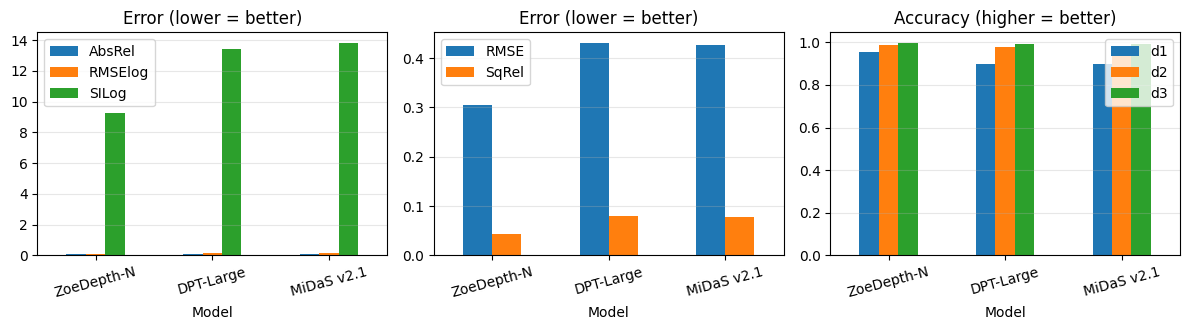

In [10]:
# Bar charts of the headline metrics
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, cols, t in zip(axs, [["AbsRel","RMSElog","SILog"], ["RMSE","SqRel"], ["d1","d2","d3"]],
                       ["Error (lower = better)", "Error (lower = better)", "Accuracy (higher = better)"]):
    main[cols].plot.bar(ax=ax, rot=15); ax.set_title(t); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("results/accuracy_bars.png", dpi=200); plt.show()

## 7. Efficiency: parameters, latency, FPS, memory

In [11]:
eff = pd.DataFrame(EFF).T[["Params (M)", "Latency (ms)", "FPS", "Peak VRAM (MB)"]]; eff.index.name = "Model"
eff.round(2).to_csv("results/efficiency.csv"); print("Marigold V2 latency includes model loading, so treat it as an upper bound.") if "Marigold V2" in eff.index else None
eff.round(2)

,Params (M),Latency (ms),FPS,Peak VRAM (MB)
Model,,,,
ZoeDepth-N,343.79,388.87,2.57,1824.89
DPT-Large,343.03,183.64,5.45,1506.97
MiDaS v2.1,105.36,78.05,12.81,528.91


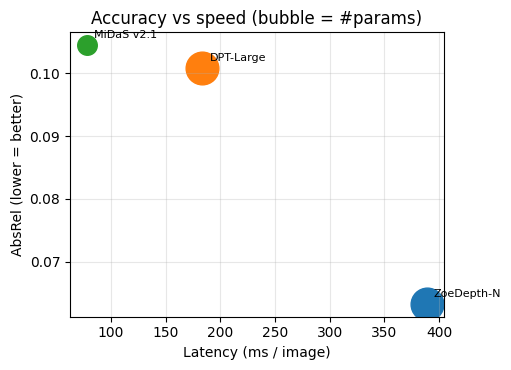

In [12]:
# Accuracy vs speed
fig, ax = plt.subplots(figsize=(5.2, 3.8))
for n in MODELS:
    if eff.loc[n, "Latency (ms)"] != eff.loc[n, "Latency (ms)"]: continue
    ax.scatter(eff.loc[n, "Latency (ms)"], main.loc[n, "AbsRel"], s=(eff.loc[n, "Params (M)"] if eff.loc[n, "Params (M)"] == eff.loc[n, "Params (M)"] else 100)*1.5+40)
    ax.annotate(n, (eff.loc[n, "Latency (ms)"], main.loc[n, "AbsRel"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Latency (ms / image)"); ax.set_ylabel("AbsRel (lower = better)")
ax.set_title("Accuracy vs speed (bubble = #params)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/accuracy_vs_speed.png", dpi=200); plt.show()

## 8. Error by depth range and per-image distribution

AbsRel by ground-truth depth range:


,near (0-2 m),mid (2-4 m),far (4-10 m)
Model,,,
ZoeDepth-N,0.0739,0.0693,0.1576
DPT-Large,0.1236,0.1122,0.2238
MiDaS v2.1,0.1367,0.1131,0.2223


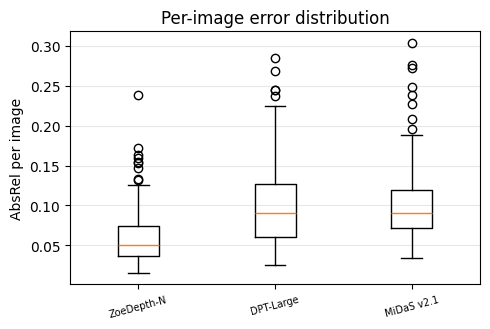

Win rate (lowest per-image AbsRel):
ZoeDepth-N    91.0
DPT-Large      5.0
MiDaS v2.1     4.0


In [13]:
bins = [(0, 2), (2, 4), (4, 10)]; names_b = ["near (0-2 m)", "mid (2-4 m)", "far (4-10 m)"]
rows = []
for n, m in MODELS.items():
    acc_b = {k: [] for k in names_b}
    for (img, gt), p in zip(DATA, PRED[n]):
        mask = valid_mask(gt); d = to_depth(p, m.kind, gt, mask, "lsq")
        for (lo, hi), k in zip(bins, names_b):
            mb = mask & (gt >= lo) & (gt < hi)
            if mb.sum() > 50: acc_b[k].append(np.mean(np.abs(d[mb] - gt[mb]) / gt[mb]))
    rows.append({"Model": n, **{k: np.mean(v) for k, v in acc_b.items()}})
rng_df = pd.DataFrame(rows).set_index("Model"); rng_df.round(4).to_csv("results/error_by_range.csv")
print("AbsRel by ground-truth depth range:"); display(rng_df.round(4))

per_img = {n: [depth_metrics(to_depth(p, m.kind, gt, valid_mask(gt), "lsq"), gt, valid_mask(gt))["AbsRel"]
               for (img, gt), p in zip(DATA, PRED[n])] for n, m in MODELS.items()}
pd.DataFrame(per_img).to_csv("results/per_image_absrel.csv", index=False)
plt.figure(figsize=(5, 3.4)); plt.boxplot(list(per_img.values())); plt.xticks(range(1, len(per_img) + 1), list(per_img), rotation=15, fontsize=7); plt.ylabel("AbsRel per image")
plt.title("Per-image error distribution"); plt.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("results/per_image_boxplot.png", dpi=200); plt.show()
print("Win rate (lowest per-image AbsRel):")
W = pd.DataFrame(per_img); print((W.idxmin(axis=1).value_counts(normalize=True)*100).round(1).to_string())

## 9. Qualitative comparison

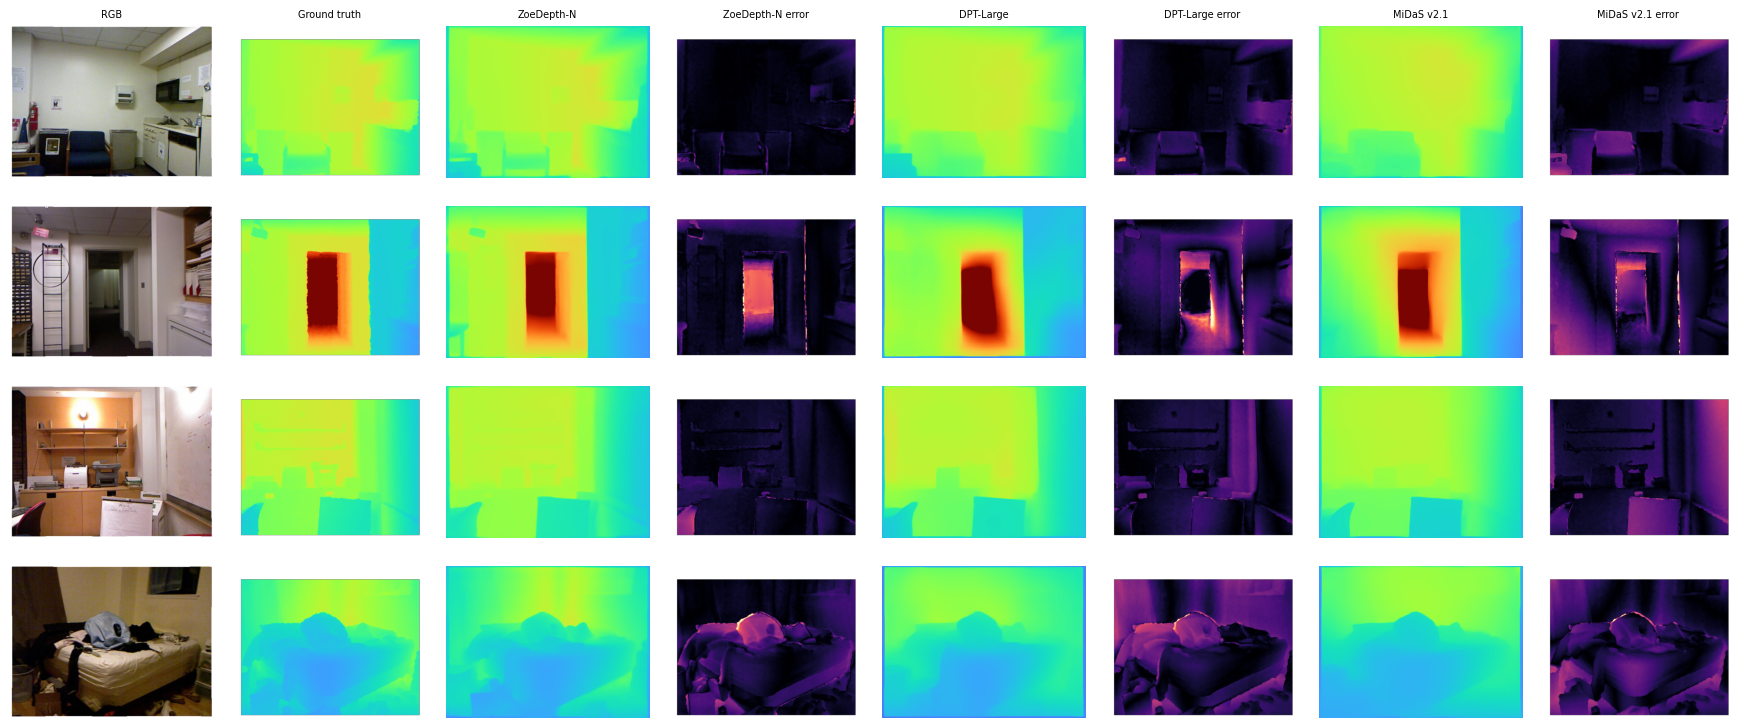

In [14]:
def colorize(d, vmin, vmax): return plt.cm.turbo(np.clip((d - vmin) / (vmax - vmin + 1e-9), 0, 1))
IDX = [i for i in [0, 7, 15, 30] if i < len(DATA)]
names = list(MODELS)
fig, axs = plt.subplots(len(IDX), 2 + 2*len(names), figsize=(2.2*(2+2*len(names)), 1.9*len(IDX)), squeeze=False)
for r, i in enumerate(IDX):
    img, gt = DATA[i]; mask = valid_mask(gt)
    axs[r, 0].imshow(img); axs[r, 1].imshow(colorize(np.where(mask, gt, np.nan), 0, 6))
    for c, n in enumerate(names):
        d = to_depth(PRED[n][i], MODELS[n].kind, gt, mask, "lsq")
        axs[r, 2 + 2*c].imshow(colorize(d, 0, 6))
        axs[r, 3 + 2*c].imshow(np.where(mask, np.abs(d - gt) / gt, np.nan), cmap="magma", vmin=0, vmax=.5)
    if r == 0:
        for c, t in enumerate(["RGB", "Ground truth"] + sum([[n, n + " error"] for n in names], [])):
            axs[0, c].set_title(t, fontsize=7)
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("results/qualitative.png", dpi=200); plt.show()

## 10. Export
Download `results.zip` and share the CSVs to fill the report tables.

In [15]:
!zip -qr results.zip results && ls -la results

total 3240
drwxr-xr-x 2 root root    4096 Nov 18 10:06 .
drwxr-xr-x 5 root root    4096 Nov 18 10:06 ..
-rw-r--r-- 1 root root     685 Nov 18 10:05 accuracy_all_protocols.csv
-rw-r--r-- 1 root root   82867 Nov 18 10:05 accuracy_bars.png
-rw-r--r-- 1 root root     274 Nov 18 10:05 accuracy_main.csv
-rw-r--r-- 1 root root   55672 Nov 18 10:05 accuracy_vs_speed.png
-rw-r--r-- 1 root root     161 Nov 18 10:05 efficiency.csv
-rw-r--r-- 1 root root     139 Nov 18 10:06 error_by_range.csv
-rw-r--r-- 1 root root    6010 Nov 18 10:06 per_image_absrel.csv
-rw-r--r-- 1 root root   55589 Nov 18 10:06 per_image_boxplot.png
-rw-r--r-- 1 root root 3082027 Nov 18 10:06 qualitative.png
